# Data Visualization: Turning Retail Sales Data into a Visual Story
**Name:** Abhay Kumar Verma  |  **Roll No:** 2026m01410112

**Project 2, Data Analyst Training Program.** This notebook cleans the retail dataset and generates all charts used in the report (13 charts covering line, bar, histogram, box plot, scatter, donut and heatmap). Run it from the project root so `data/` and `clean_data.py` are found.

## 1. Setup, cleaning and palette
The notebook uses one palette throughout: blue for normal data, orange to highlight the point being made, grey for reference lines.

In [1]:
import json
import os
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns

from clean_data import load_and_clean

OUT = "charts"
os.makedirs(OUT, exist_ok=True)

# ---- consistent palette: one base colour, one highlight colour, one neutral ----
BLUE = "#2a78d6"      # default data colour
ORANGE = "#eb6834"    # highlight: the point being made
GREY = "#8a8985"      # neutral / reference lines
INK = "#1f1f1f"
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#eaf2fc", "#2a78d6", "#0e2f5c"])
DIV = LinearSegmentedColormap.from_list("div", [ORANGE, "#f2f2f0", BLUE])
SEGMENT_COLORS = [BLUE, ORANGE, "#1baf7a"]

plt.rcParams.update({
    "figure.dpi": 150, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 10, "axes.edgecolor": "#bbbbb8", "axes.labelcolor": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#ececea", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "xtick.color": INK, "ytick.color": INK,
})

df = load_and_clean()
stats = {}


def save(fig, name):
    fig.savefig(f"{OUT}/{name}.png", facecolor="white")
    plt.show()
    plt.close(fig)


def inr_m(x, _=None):
    return f"₹{x/1e6:,.1f}M"

### Data cleaning summary
`clean_data.py` removes duplicates, parses the four mixed date formats, standardises Region/Gender labels, blanks impossible Age (<18 or >100) and Discount (outside 0–0.5) values, and caps Income at the 99th percentile for plotting.

In [2]:
raw = pd.read_csv('data/retail_customer_sales_dataset.csv')
print('Raw shape  :', raw.shape)
print('Clean shape:', df.shape)
_ = load_and_clean(verbose=True)
print('\nRegions:', sorted(df.Region.unique()), '| Genders:', sorted(df.Gender.unique()))
print('Date range:', df.Order_Date.min().date(), 'to', df.Order_Date.max().date())
df.head()

Raw shape  : (7084, 24)
Clean shape: (7000, 27)
                raw_rows: 7084
        after_exact_dups: 7023
           after_id_dups: 7000
   delivery_before_order: 15
             invalid_age: 6
        invalid_discount: 6
        income_cap_99pct: 157204.63
              final_rows: 7000

Regions: ['East', 'North', 'South', 'West'] | Genders: ['Female', 'Male']
Date range: 2023-01-01 to 2024-12-31


,Transaction_ID,Customer_ID,Order_Date,Delivery_Date,Age,Gender,Income,Region,State,City,...,Cost,Profit,Payment_Method,Delivery_Mode,Customer_Rating,Satisfaction_Level,Returned,Year,Month,Income_Capped
0,TXN205933,CUST10816,2023-12-19,2023-12-25,38.0,Male,62828.52,West,Gujarat,Surat,...,1204.47,606.93,Debit Card,Standard,3.0,Low,No,2023,2023-12-01,62828.52
1,TXN201247,CUST10916,2023-09-30,2023-10-04,42.0,Male,50952.64,North,Haryana,Gurugram,...,17137.06,6331.27,Credit Card,Standard,3.0,High,No,2023,2023-09-01,50952.64
2,TXN202714,CUST11352,2023-01-12,2023-01-20,41.0,Male,60476.00,East,Jharkhand,Ranchi,...,1577.83,1010.03,Debit Card,Express,3.0,Medium,No,2023,2023-01-01,60476.00
3,TXN206797,CUST11551,2024-06-06,2024-06-10,33.0,Male,41516.94,West,Gujarat,Surat,...,556.78,320.97,Debit Card,Standard,3.0,Medium,No,2024,2024-06-01,41516.94
4,TXN203937,CUST10855,2024-09-23,2024-09-30,29.0,Female,95727.49,North,Haryana,Gurugram,...,5528.47,2799.81,UPI,Express,1.0,Low,No,2024,2024-09-01,95727.49


## 2. Charts

### Chart 1 LINE: Monthly sales trend ------------------------------------------------

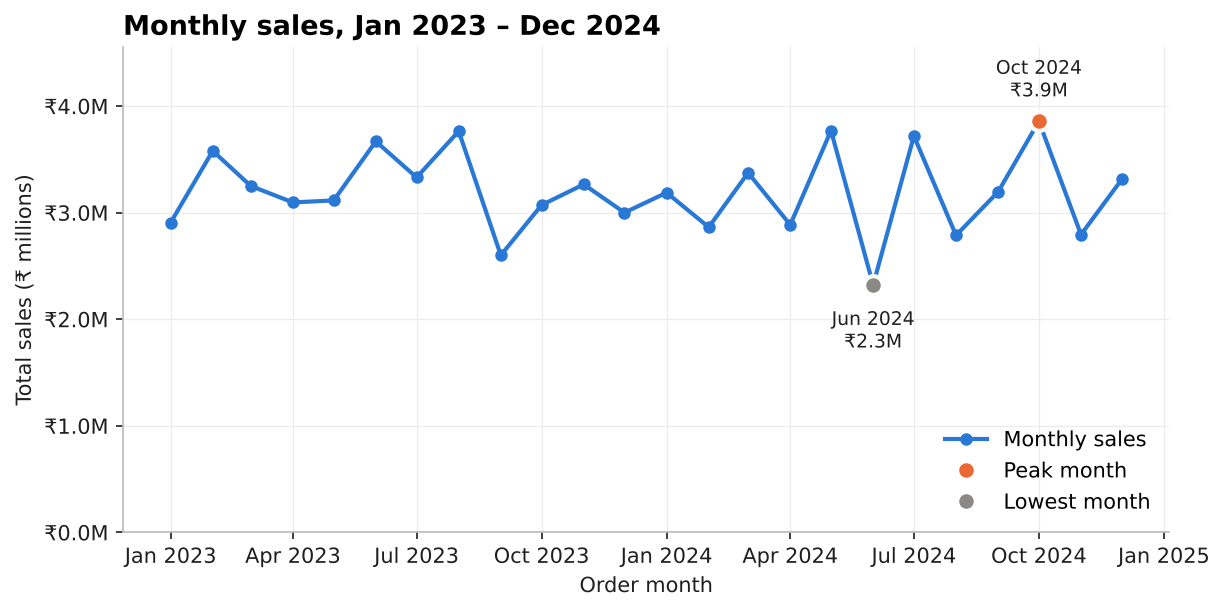

In [3]:
# 1. LINE: monthly sales trend ------------------------------------------------
m = df.groupby("Month")["Sales"].sum()
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(m.index, m.values, color=BLUE, lw=2, marker="o", ms=5, label="Monthly sales")
ax.plot(m.idxmax(), m.max(), "o", color=ORANGE, ms=9, mec="white", mew=2, label="Peak month")
ax.plot(m.idxmin(), m.min(), "o", color=GREY, ms=9, mec="white", mew=2, label="Lowest month")
ax.annotate(f"{m.idxmax():%b %Y}\n{inr_m(m.max())}", (m.idxmax(), m.max()),
            xytext=(0, 12), textcoords="offset points", ha="center", fontsize=9, color=INK)
ax.annotate(f"{m.idxmin():%b %Y}\n{inr_m(m.min())}", (m.idxmin(), m.min()),
            xytext=(0, -30), textcoords="offset points", ha="center", fontsize=9, color=INK)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(inr_m))
ax.set_ylim(0, m.max() * 1.18)
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set_title("Monthly sales, Jan 2023 – Dec 2024")
ax.set_xlabel("Order month"); ax.set_ylabel("Total sales (₹ millions)")
ax.legend(frameon=False, loc="lower right")
save(fig, "01_line_monthly_sales")
y = df.groupby("Year")["Sales"].sum()
h1 = m[:12].mean(); h2 = m[12:].mean()
stats["line"] = dict(peak=str(m.idxmax().date()), peak_val=m.max(), low=str(m.idxmin().date()),
                     low_val=m.min(), y2023=y[2023], y2024=y[2024],
                     growth=(y[2024] / y[2023] - 1) * 100, avg_month=m.mean(), cv=m.std() / m.mean() * 100)
# month-of-year seasonality
moy = df.groupby(df.Order_Date.dt.month)["Sales"].sum()
stats["line"]["best_moy"] = int(moy.idxmax()); stats["line"]["worst_moy"] = int(moy.idxmin())

**Figure 1: Monthly sales, Jan 2023 – Dec 2024**

*Insight:* Sales were almost flat: ₹38.7M in 2023 and ₹38.1M in 2024 (-1.5%). Monthly figures swing a lot (peak Oct 2024 at ₹3.9M, low Jun 2024 at ₹2.3M), but there is no clear trend or repeating seasonal pattern. The business looks stable but not growing, so growth will have to come from somewhere else.

### Chart 2 BAR: Sales by region -----------------------------------------------------

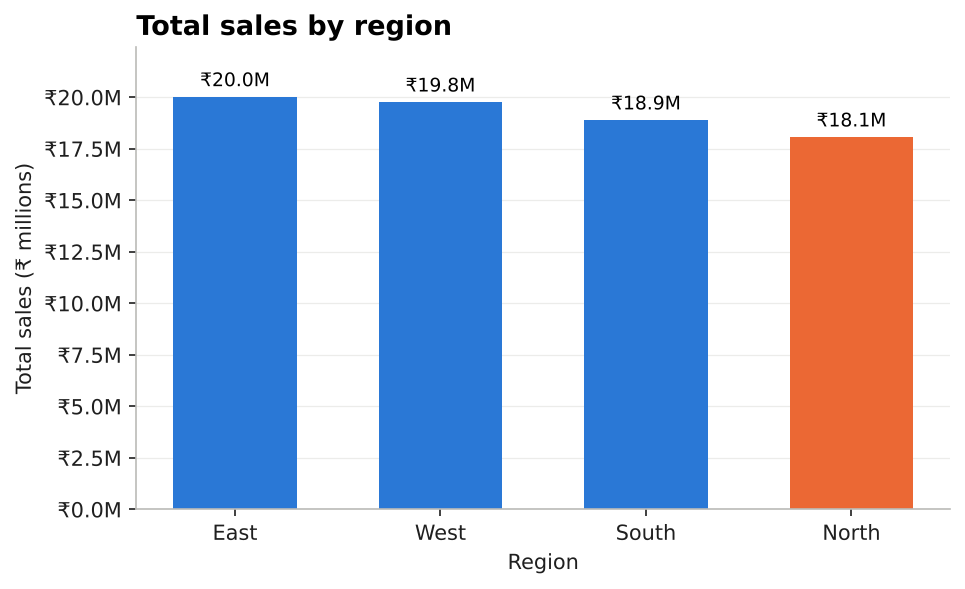

In [4]:
# 2. BAR: sales by region -----------------------------------------------------
r = df.groupby("Region")["Sales"].sum().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 4))
cols = [ORANGE if k == r.idxmin() else BLUE for k in r.index]
bars = ax.bar(r.index, r.values, color=cols, width=0.6)
ax.bar_label(bars, labels=[inr_m(v) for v in r.values], padding=3, fontsize=9)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(inr_m)); ax.set_ylim(0, r.max() * 1.12)
ax.grid(axis="x", visible=False)
ax.set_title("Total sales by region"); ax.set_xlabel("Region"); ax.set_ylabel("Total sales (₹ millions)")
save(fig, "02_bar_sales_by_region")
stats["region"] = dict(r.round(0).to_dict(), top=r.idxmax(), bottom=r.idxmin(),
                       gap_pct=(r.max() / r.min() - 1) * 100, total=r.sum())

**Figure 2: Total sales by region**

*Insight:* East leads with ₹20.0M, while North (highlighted) trails at ₹18.1M, a gap of 11%. The four regions are fairly close, so no region is failing. North is still the clearest candidate for a targeted sales push.

### Chart 3 BAR: Sales by category ---------------------------------------------------

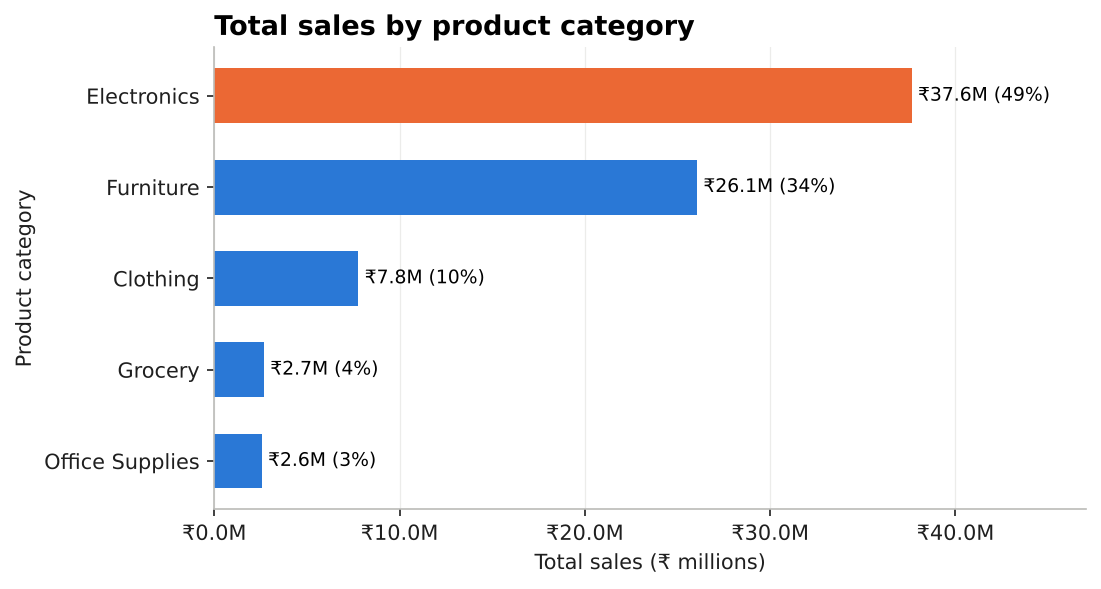

In [5]:
# 3. BAR: sales by category ---------------------------------------------------
c = df.groupby("Product_Category")["Sales"].sum().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7.5, 4))
cols = [ORANGE if k == c.idxmax() else BLUE for k in c.index]
bars = ax.barh(c.index[::-1], c.values[::-1], color=cols[::-1], height=0.6)
ax.bar_label(bars, labels=[f"{inr_m(v)} ({v/c.sum():.0%})" for v in c.values[::-1]], padding=3, fontsize=9)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(inr_m)); ax.set_xlim(0, c.max() * 1.25)
ax.grid(axis="y", visible=False)
ax.set_title("Total sales by product category"); ax.set_xlabel("Total sales (₹ millions)"); ax.set_ylabel("Product category")
save(fig, "03_bar_sales_by_category")
stats["category"] = dict(c.round(0).to_dict(), top=c.idxmax(), bottom=c.idxmin(),
                         top_share=c.max() / c.sum() * 100, bottom_share=c.min() / c.sum() * 100)

**Figure 3: Total sales by product category**

*Insight:* Electronics alone brings in 49% of all sales, and with Furniture the two categories make up 83% of revenue. Office Supplies contributes only 3.3%. The business depends heavily on two high-ticket categories, so stock and marketing there matter most.

### Chart 4 HISTOGRAM: Age -----------------------------------------------------------

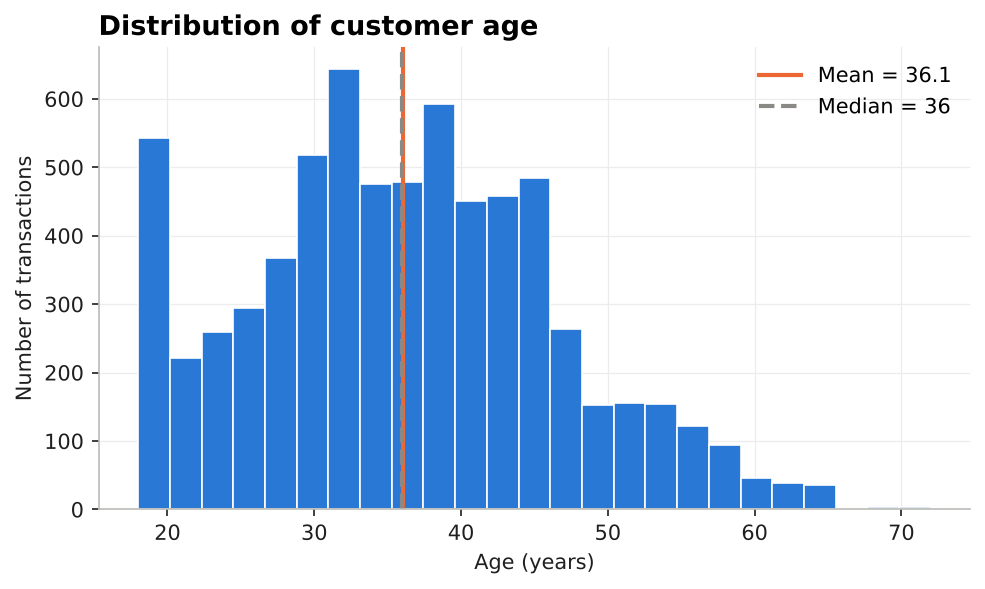

In [6]:
# 4. HISTOGRAM: age -----------------------------------------------------------
age = df["Age"].dropna()
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.hist(age, bins=25, color=BLUE, edgecolor="white", linewidth=0.8)
ax.axvline(age.mean(), color=ORANGE, lw=2, label=f"Mean = {age.mean():.1f}")
ax.axvline(age.median(), color=GREY, lw=2, ls="--", label=f"Median = {age.median():.0f}")
ax.set_title("Distribution of customer age"); ax.set_xlabel("Age (years)"); ax.set_ylabel("Number of transactions")
ax.legend(frameon=False)
save(fig, "04_hist_age")
stats["age"] = dict(mean=age.mean(), median=age.median(), skew=age.skew(), min=age.min(), max=age.max(),
                    share_25_45=((age >= 25) & (age <= 45)).mean() * 100)

**Figure 4: Distribution of customer age**

*Insight:* Ages range from 18 to 72 and cluster around the mean of 36.1 (median 36). Skewness is only 0.27, so the distribution is almost symmetric. About 67% of transactions come from customers aged 25–45, which is the core audience for campaigns.

### Chart 5 HISTOGRAM: Income (capped at 99th percentile) ------------------------------

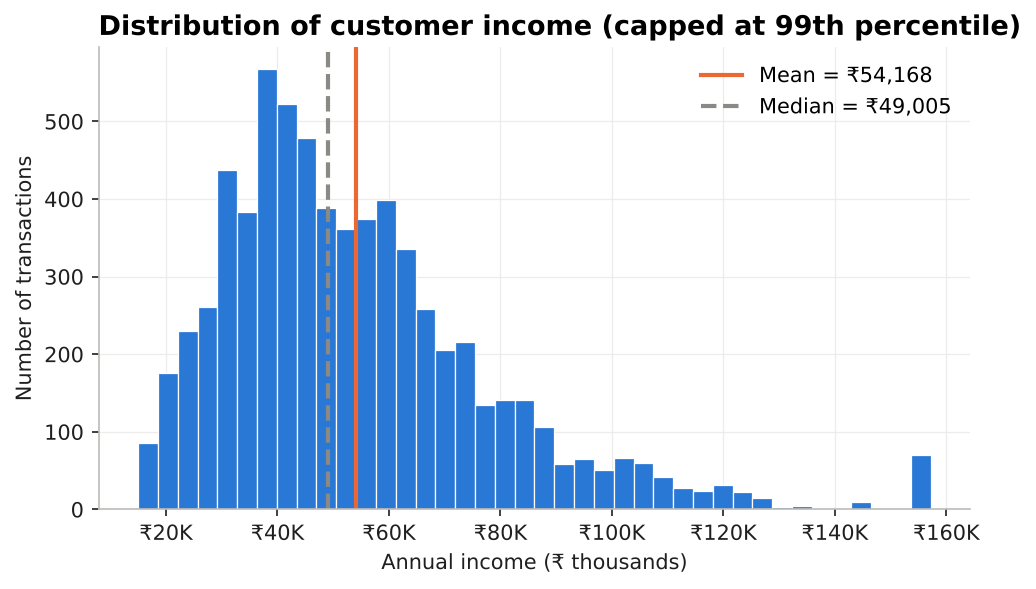

In [7]:
# 5. HISTOGRAM: income (capped at 99th percentile) ------------------------------
inc = df["Income_Capped"].dropna()
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.hist(inc, bins=40, color=BLUE, edgecolor="white", linewidth=0.6)
ax.axvline(inc.mean(), color=ORANGE, lw=2, label=f"Mean = ₹{inc.mean():,.0f}")
ax.axvline(inc.median(), color=GREY, lw=2, ls="--", label=f"Median = ₹{inc.median():,.0f}")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"₹{x/1000:,.0f}K"))
ax.set_title("Distribution of customer income (capped at 99th percentile)")
ax.set_xlabel("Annual income (₹ thousands)"); ax.set_ylabel("Number of transactions")
ax.legend(frameon=False)
save(fig, "05_hist_income")
raw_inc = df["Income"].dropna()
stats["income"] = dict(mean=inc.mean(), median=inc.median(), skew_capped=inc.skew(), skew_raw=raw_inc.skew(),
                       raw_max=raw_inc.max(), cap=df["Income"].quantile(.99))

**Figure 5: Distribution of customer income**

*Insight:* Income is right-skewed: the mean (₹54,168) sits above the median (₹49,005) because a few high earners pull the average up. Skewness is 1.34 even after capping at the 99th percentile (₹157,205); the raw data reaches ₹1,750,890. Most customers earn modestly, so pricing and offers should be set around the median (₹49,005).

### Chart 6 BOX: Sales by category ---------------------------------------------------

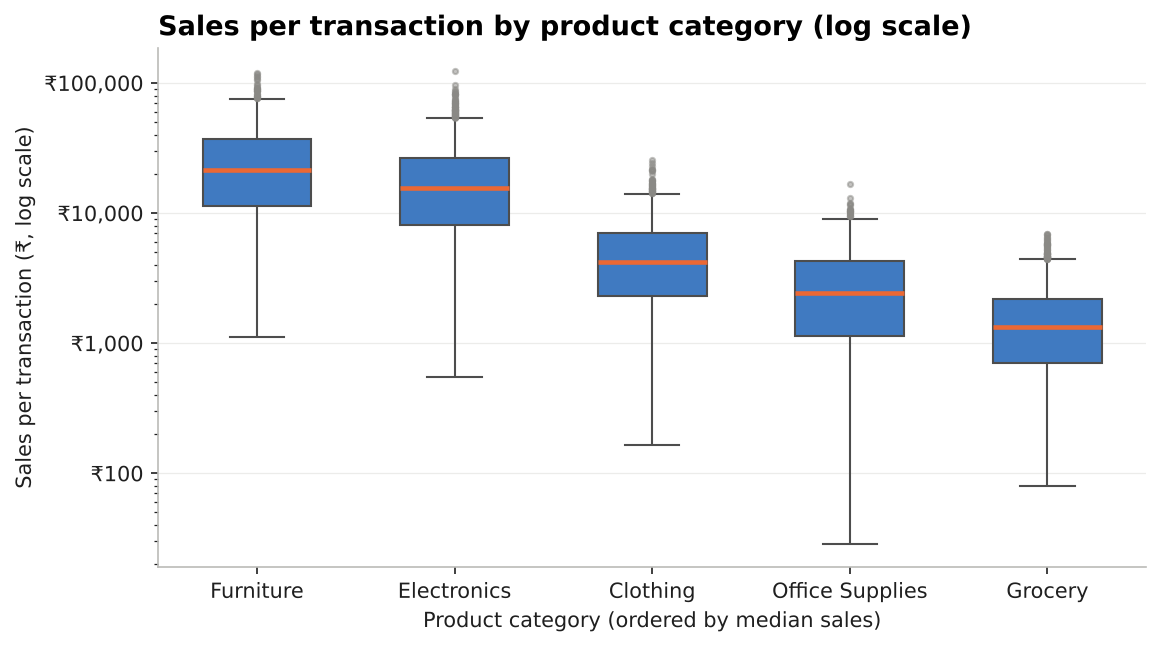

In [8]:
# 6. BOX: sales by category ---------------------------------------------------
order = df.groupby("Product_Category")["Sales"].median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(8.5, 4.5))
sns.boxplot(data=df, x="Product_Category", y="Sales", order=order, color=BLUE, width=0.55,
            fliersize=2.5, linewidth=1, flierprops=dict(markerfacecolor=GREY, markeredgecolor=GREY, alpha=.5),
            medianprops=dict(color=ORANGE, lw=2.2), ax=ax)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"₹{x:,.0f}"))
ax.set_title("Sales per transaction by product category (log scale)")
ax.set_xlabel("Product category (ordered by median sales)"); ax.set_ylabel("Sales per transaction (₹, log scale)")
ax.grid(axis="x", visible=False)
save(fig, "06_box_sales_by_category")
g = df.groupby("Product_Category")["Sales"]
q1, q3 = g.quantile(.25), g.quantile(.75)
iqr = q3 - q1
outl = {k: int(((df[df.Product_Category == k].Sales > q3[k] + 1.5 * iqr[k])).sum()) for k in order}
stats["box"] = dict(median=g.median().round(0).to_dict(), iqr=iqr.round(0).to_dict(), outliers=outl,
                    top=order[0], bottom=order[-1])

**Figure 7: Sales per transaction by product category**

*Insight:* Typical order value differs by more than 15 times across categories, from a median of ₹21,490 for Furniture to ₹1,324 for Grocery. Furniture and Electronics also have the widest spread, and Electronics has the most high-value outliers (56). Big-ticket orders in these categories drive revenue, so they deserve special handling in delivery and returns.

### Chart 7 SCATTER: Sales vs profit -------------------------------------------------

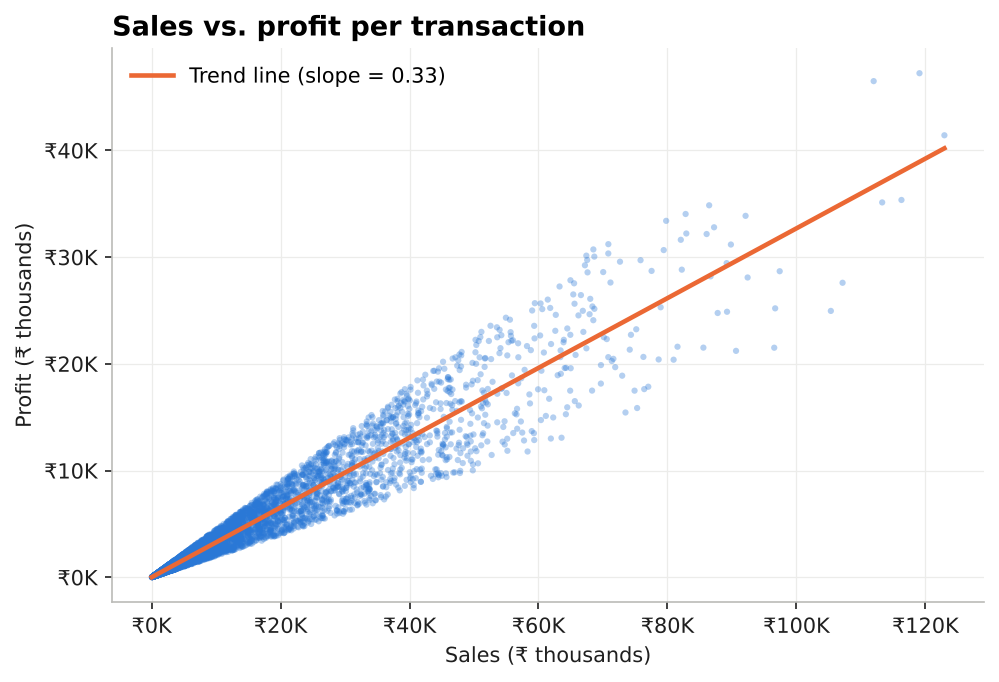

In [9]:
# 7. SCATTER: sales vs profit -------------------------------------------------
fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.scatter(df.Sales, df.Profit, s=9, alpha=.35, color=BLUE, edgecolors="none")
k, b = np.polyfit(df.Sales, df.Profit, 1)
xs = np.linspace(df.Sales.min(), df.Sales.max(), 100)
ax.plot(xs, k * xs + b, color=ORANGE, lw=2.2, label=f"Trend line (slope = {k:.2f})")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"₹{x/1000:,.0f}K"))
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"₹{x/1000:,.0f}K"))
ax.set_title("Sales vs. profit per transaction"); ax.set_xlabel("Sales (₹ thousands)"); ax.set_ylabel("Profit (₹ thousands)")
ax.legend(frameon=False, loc="upper left")
save(fig, "07_scatter_sales_profit")
stats["sales_profit"] = dict(r=df.Sales.corr(df.Profit), slope=k, margin=df.Profit.sum() / df.Sales.sum() * 100,
                             loss_txns=int((df.Profit < 0).sum()))

**Figure 9: Sales vs. profit per transaction**

*Insight:* Sales and profit move almost in lockstep (r = 0.97); each extra rupee of sales adds about ₹0.33 of profit. No transaction in the cleaned data made a loss, and the overall margin is 32.7%. Because the relationship is linear and tight, growing sales is the reliable way to grow profit.

### Chart 8 SCATTER: Discount vs profit -----------------------------------------------

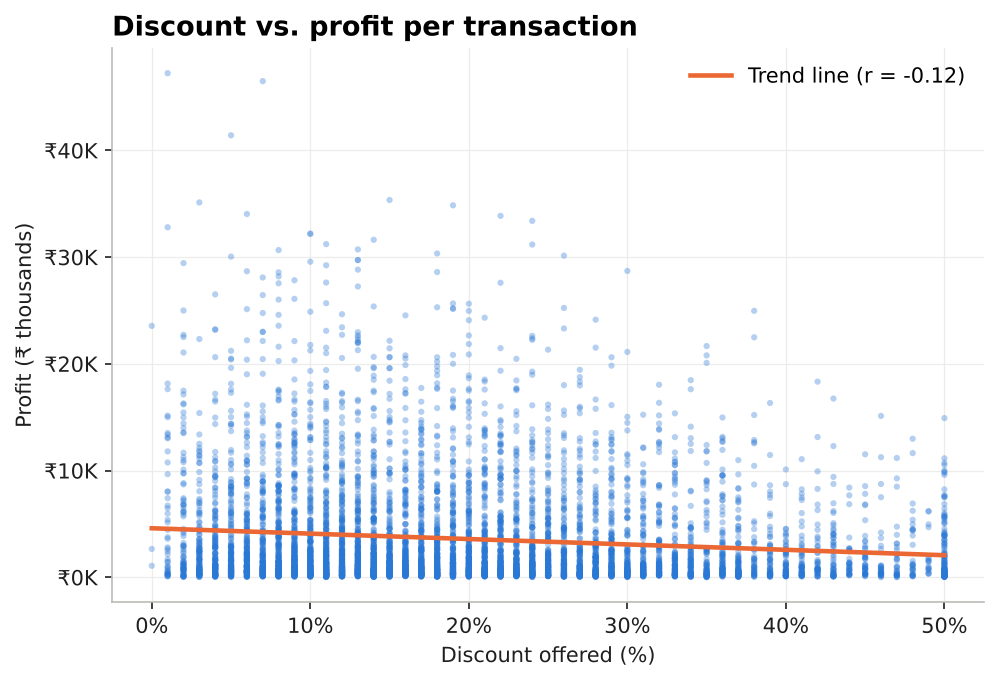

In [10]:
# 8. SCATTER: discount vs profit -----------------------------------------------
d2 = df.dropna(subset=["Discount"])
fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.scatter(d2.Discount, d2.Profit, s=9, alpha=.35, color=BLUE, edgecolors="none")
k2, b2 = np.polyfit(d2.Discount, d2.Profit, 1)
xs = np.linspace(0, .5, 50)
ax.plot(xs, k2 * xs + b2, color=ORANGE, lw=2.2, label=f"Trend line (r = {d2.Discount.corr(d2.Profit):.2f})")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"₹{x/1000:,.0f}K"))
ax.set_title("Discount vs. profit per transaction"); ax.set_xlabel("Discount offered (%)"); ax.set_ylabel("Profit (₹ thousands)")
ax.legend(frameon=False, loc="upper right")
save(fig, "08_scatter_discount_profit")
d2b = d2.assign(bucket=pd.cut(d2.Discount, [0, .1, .2, .3, .4, .5], include_lowest=True))
mm = d2b.groupby("bucket", observed=True).apply(lambda t: t.Profit.sum() / t.Sales.sum() * 100)
stats["disc_profit"] = dict(r=d2.Discount.corr(d2.Profit), slope=k2, margin_low=mm.iloc[0], margin_high=mm.iloc[-1])

**Figure 10: Discount vs. profit per transaction**

*Insight:* There is only a weak negative link between discount and profit (r = -0.12), and the points form a shapeless cloud. Margin is 32.9% for the smallest discounts and 32.4% for the largest. In this data, deeper discounts do not visibly reduce margin, so they should be judged by whether they lift sales volume.

### Chart 9 DONUT: Sales share by segment ---------------------------------------------

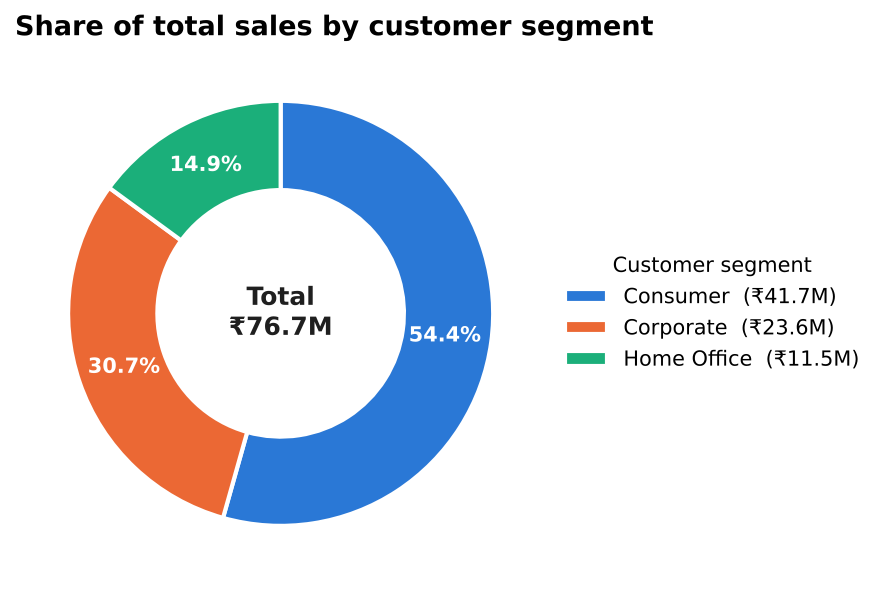

In [11]:
# 9. DONUT: sales share by segment ---------------------------------------------
sg = df.groupby("Customer_Segment")["Sales"].sum().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(6.2, 4.6))
wedges, _, autot = ax.pie(sg.values, colors=SEGMENT_COLORS, startangle=90, counterclock=False,
                          autopct="%1.1f%%", pctdistance=.78, wedgeprops=dict(width=.42, edgecolor="white", linewidth=2),
                          textprops=dict(color="white", fontweight="bold"))
ax.text(0, 0, f"Total\n{inr_m(sg.sum())}", ha="center", va="center", fontsize=12, fontweight="bold", color=INK)
ax.legend(wedges, [f"{k}  ({inr_m(v)})" for k, v in sg.items()], title="Customer segment",
          loc="center left", bbox_to_anchor=(1, .5), frameon=False)
ax.set_title("Share of total sales by customer segment")
save(fig, "09_donut_segment_share")
cnt = df.Customer_Segment.value_counts(normalize=True) * 100
stats["segment"] = dict(share=(sg / sg.sum() * 100).round(1).to_dict(), txn_share=cnt.round(1).to_dict(),
                        aov=df.groupby("Customer_Segment")["Sales"].mean().round(0).to_dict())

**Figure 6: Share of total sales by customer segment**

*Insight:* Consumers generate 54% of sales, Corporate 31% and Home Office 15%. Average order values are very similar across segments (₹10,864–₹11,141), so each segment's share follows the number of orders it places. Growing a segment therefore means winning more orders, since order size is about the same everywhere.

### Chart 10 HEATMAP: Correlation matrix ---------------------------------------------

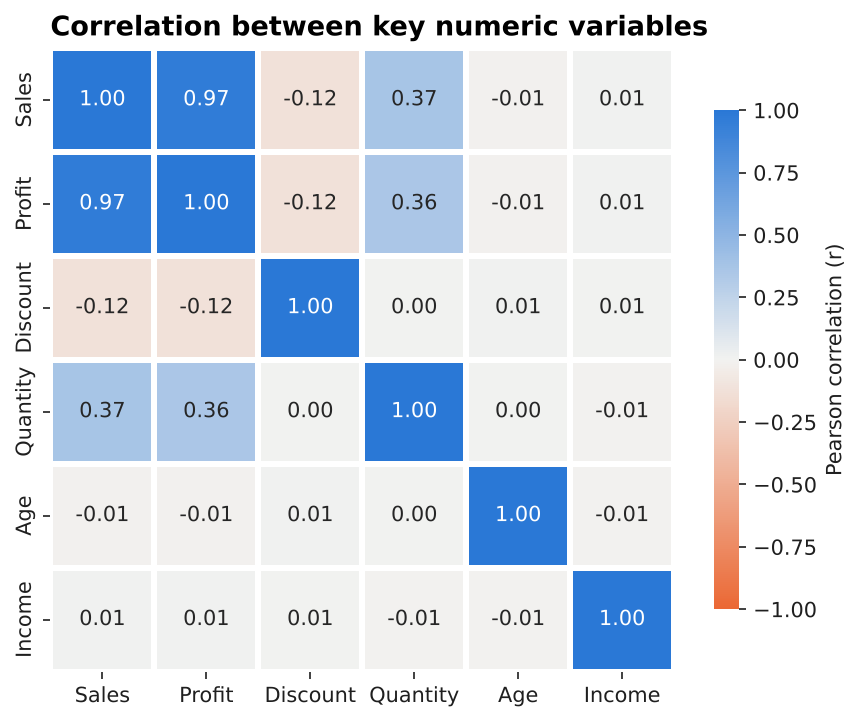

In [12]:
# 10. HEATMAP: correlation matrix ---------------------------------------------
cols = ["Sales", "Profit", "Discount", "Quantity", "Age", "Income"]
corr = df[cols].corr()
fig, ax = plt.subplots(figsize=(6.8, 5.4))
sns.heatmap(corr, annot=True, fmt=".2f", cmap=DIV, vmin=-1, vmax=1, center=0, linewidths=2, linecolor="white",
            square=True, cbar_kws=dict(label="Pearson correlation (r)", shrink=.8), ax=ax)
ax.grid(False); ax.set_title("Correlation between key numeric variables")
ax.set_xlabel(""); ax.set_ylabel("")
save(fig, "10_heatmap_correlation")
pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
stats["corr"] = dict(sales_profit=corr.loc["Sales", "Profit"], sales_qty=corr.loc["Sales", "Quantity"],
                     sales_disc=corr.loc["Sales", "Discount"], profit_disc=corr.loc["Profit", "Discount"],
                     sales_income=corr.loc["Sales", "Income"], sales_age=corr.loc["Sales", "Age"],
                     weakest=str(pairs.abs().idxmin()), weakest_val=pairs.loc[pairs.abs().idxmin()])

**Figure 12: Correlation between key numeric variables**

*Insight:* Sales and profit are strongly correlated (0.97), and quantity has a moderate link to both (0.37). Discount, age and income are almost unrelated to sales (all within ±0.12). Customer age and income do not explain spending here, so order quantity and product mix are the better places to look.

### Chart 11 HEATMAP: Avg sales, category x region -----------------------------------

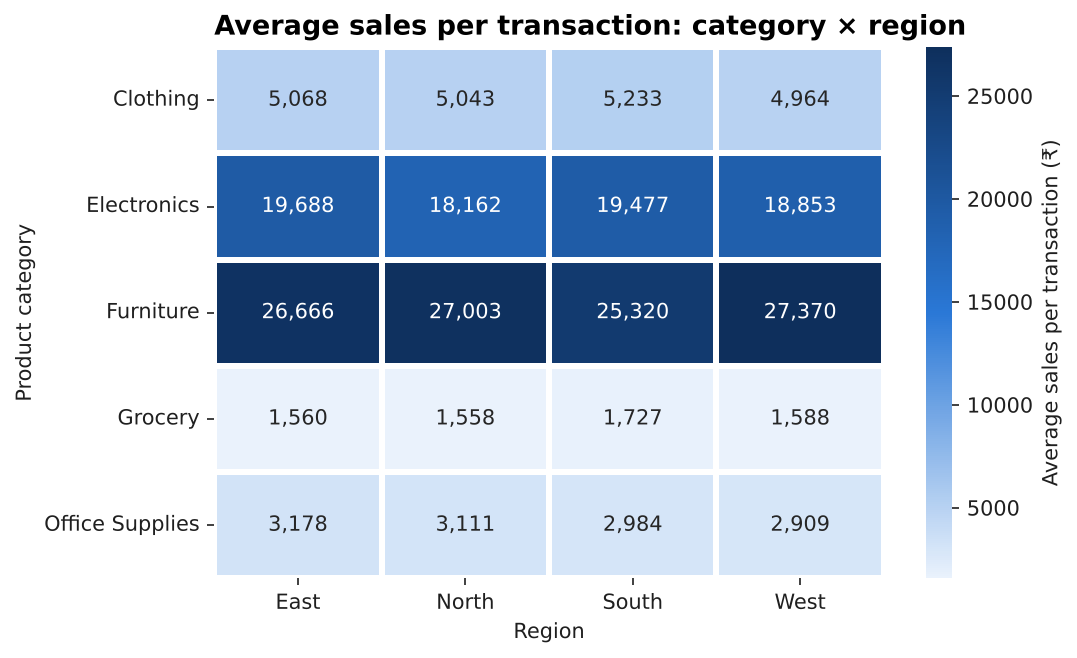

In [13]:
# 11. HEATMAP: avg sales, category x region -----------------------------------
pv = df.pivot_table(index="Product_Category", columns="Region", values="Sales", aggfunc="mean")
fig, ax = plt.subplots(figsize=(7.2, 4.6))
sns.heatmap(pv, annot=True, fmt=",.0f", cmap=SEQ, linewidths=2, linecolor="white",
            cbar_kws=dict(label="Average sales per transaction (₹)"), ax=ax)
ax.grid(False); ax.set_title("Average sales per transaction: category × region")
ax.set_xlabel("Region"); ax.set_ylabel("Product category")
save(fig, "11_heatmap_category_region")
st = pv.stack()
stats["pivot"] = dict(max_cell=str(st.idxmax()), max_val=st.max(), min_cell=str(st.idxmin()), min_val=st.min(),
                      cat_range={k: (pv.loc[k].max() - pv.loc[k].min()) / pv.loc[k].mean() * 100 for k in pv.index})

**Figure 13: Average sales per transaction, category × region**

*Insight:* The product category matters far more than the region: the best cell is Furniture, West at ₹27,370, and the weakest is Grocery, North at ₹1,558. Within any one category, average sales differ by only 5–10% across regions. Regional strategy can stay broadly uniform; the differences that matter are between products.

### Chart 12 BAR: Profit margin by category ------------------------------------------

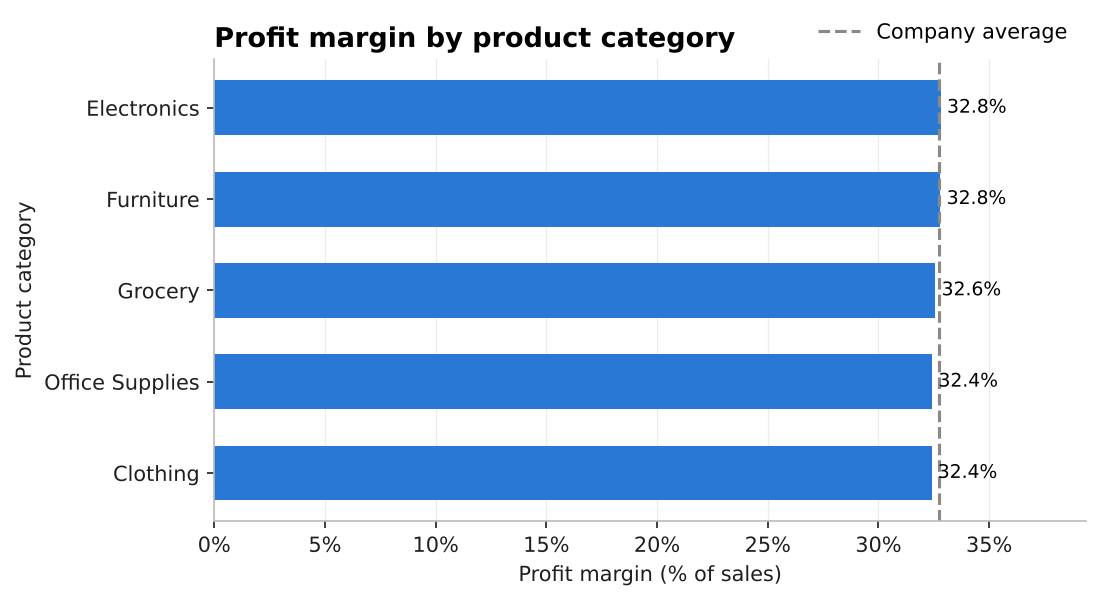

In [14]:
# 12. BAR: profit margin by category ------------------------------------------
pm = (df.groupby("Product_Category")["Profit"].sum() / df.groupby("Product_Category")["Sales"].sum() * 100).sort_values()
fig, ax = plt.subplots(figsize=(7.5, 4))
cols_ = [BLUE for k in pm.index]  # margins are near-identical, so no highlight
bars = ax.barh(pm.index, pm.values, color=cols_, height=.6)
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in pm.values], padding=3, fontsize=9)
ax.axvline(df.Profit.sum() / df.Sales.sum() * 100, color=GREY, ls="--", lw=1.5, label="Company average")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); ax.set_xlim(0, pm.max() * 1.2)
ax.grid(axis="y", visible=False); ax.legend(frameon=False, loc="upper right", bbox_to_anchor=(1, 1.12))
ax.set_title("Profit margin by product category"); ax.set_xlabel("Profit margin (% of sales)"); ax.set_ylabel("Product category")
save(fig, "12_bar_margin_by_category")
stats["margin"] = dict(pm.round(2).to_dict(), low=pm.idxmin(), high=pm.idxmax(), avg=df.Profit.sum() / df.Sales.sum() * 100)

**Figure 8: Profit margin by product category**

*Insight:* Margins are almost identical across categories, between 32.4% and 32.8%, close to the company average of 32.7%. So no category is losing money. Profit differs between categories because sales volume differs, which is why Electronics and Furniture produce most of the profit.

### Chart 13 BAR: Return rate by delivery mode ---------------------------------------

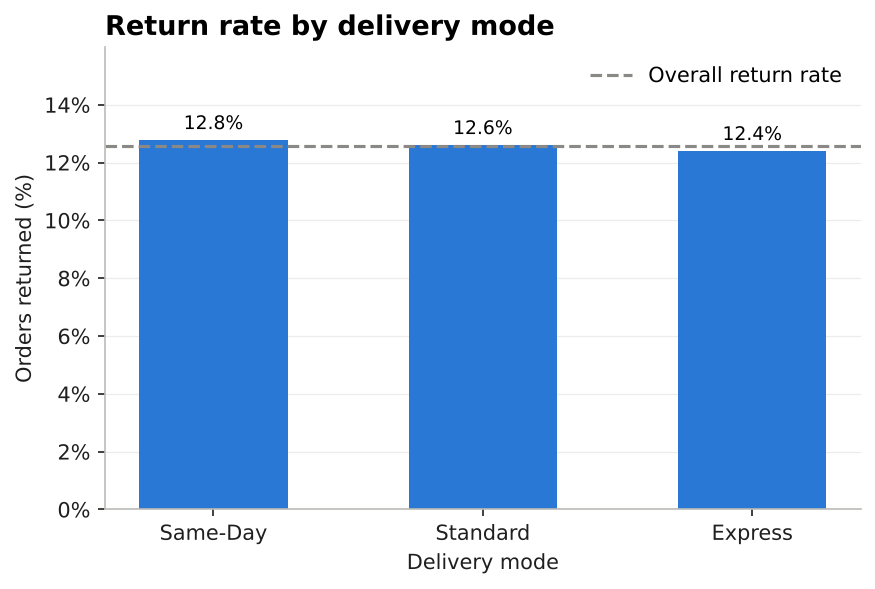

In [15]:
# 13. BAR: return rate by delivery mode ---------------------------------------
rr = (df.assign(R=(df.Returned == "Yes")).groupby("Delivery_Mode")["R"].mean() * 100).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(6.5, 4))
cols_ = [BLUE for k in rr.index]  # rates are near-identical, so no highlight
bars = ax.bar(rr.index, rr.values, color=cols_, width=.55)
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in rr.values], padding=3, fontsize=9)
ax.axhline((df.Returned == "Yes").mean() * 100, color=GREY, ls="--", lw=1.5, label="Overall return rate")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); ax.set_ylim(0, rr.max() * 1.25)
ax.grid(axis="x", visible=False); ax.legend(frameon=False)
ax.set_title("Return rate by delivery mode"); ax.set_xlabel("Delivery mode"); ax.set_ylabel("Orders returned (%)")
save(fig, "13_bar_return_by_delivery")
stats["returns"] = dict(rr.round(2).to_dict(), overall=(df.Returned == "Yes").mean() * 100, high=rr.idxmax(), low=rr.idxmin())

**Figure 11: Return rate by delivery mode**

*Insight:* About 12.6% of orders are returned, and the rate hardly changes with delivery mode (Express 12.4% to Same-Day 12.8%). Delivery speed does not seem to drive returns, so reducing them will take other changes, such as better product quality or clearer descriptions.

## 3. Headline KPIs and saved statistics

In [16]:
# headline KPIs ---------------------------------------------------------------
stats["kpi"] = dict(total_sales=df.Sales.sum(), total_profit=df.Profit.sum(), margin=df.Profit.sum() / df.Sales.sum() * 100,
                    aov=df.Sales.mean(), rows=len(df), customers=df.Customer_ID.nunique())


def conv(o):
    if isinstance(o, (np.floating, np.integer)):
        return o.item()
    return str(o)


with open(f"{OUT}/stats.json", "w") as f:
    json.dump(stats, f, indent=2, default=conv)
print("charts written:", sorted(os.listdir(OUT)))
pd.Series(stats['kpi'])

charts written: ['01_line_monthly_sales.png', '02_bar_sales_by_region.png', '03_bar_sales_by_category.png', '04_hist_age.png', '05_hist_income.png', '06_box_sales_by_category.png', '07_scatter_sales_profit.png', '08_scatter_discount_profit.png', '09_donut_segment_share.png', '10_heatmap_correlation.png', '11_heatmap_category_region.png', '12_bar_margin_by_category.png', '13_bar_return_by_delivery.png', 'stats.json']


total_sales     7.673119e+07
total_profit    2.512788e+07
margin          3.274794e+01
aov             1.096160e+04
rows            7.000000e+03
customers       1.576000e+03
dtype: float64